## Downloading Dataset

In [1]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('playground-series-s6e11', output_dir='datasets/predicting_credit_card_fraud')

print("Path to competition files:", path)

/home/theju-bot/Documents/ML Engineering/Projects/.venv/lib/python3.15/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|████████████████████████████████████████████████████████████████████████| 29.5M/29.5M [00:38<00:00, 805kB/s]

Extracting files...


Path to competition files: datasets/predicting_credit_card_fraud


## Load & explore the data set 

In [10]:
from pathlib import Path
import pandas as pd

data_dir = Path('datasets/predicting_credit_card_fraud')

train_df = pd.read_csv(data_dir/'train.csv')
test = pd.read_csv(data_dir/'test.csv')
sample_submission = pd.read_csv(data_dir/'sample_submission.csv')

In [7]:
train_df.head()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [5]:
train_df.shape

(699960, 26)

In [9]:
train_df.columns

Index(['id', 'amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes', 'merchant_category', 'card_type', 'auth_method',
       'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant',
       'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt', 'is_fraud'],
      dtype='str')

In [10]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 26 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   id                            699960 non-null  int64  
 1   amount_usd                    699960 non-null  float64
 2   hours_since_last_txn          699960 non-null  float64
 3   txn_count_last_24h            699960 non-null  int64  
 4   distance_from_home_km         699960 non-null  float64
 5   card_age_months               699960 non-null  int64  
 6   customer_age                  699960 non-null  int64  
 7   account_balance_usd           699960 non-null  float64
 8   cvv_retry_count               699960 non-null  int64  
 9   velocity_score                699960 non-null  float64
 10  time_of_day_hour              699960 non-null  int64  
 11  day_of_week                   699960 non-null  int64  
 12  merchant_risk_score           699960 non-null  float64


In [11]:
train_df.describe()

,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,is_fraud
count,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000,699960.000000
mean,349979.500000,79.893068,6.633734,2.984092,13.587575,46.862982,51.430286,2064.998070,0.085472,18.929445,11.761915,2.981733,35.217648,0.152769,0.016700
std,202061.191549,205.173538,6.290133,1.498998,11.617325,5.579190,17.899150,3400.132922,0.289524,10.864385,6.869164,2.001652,12.628361,0.381126,0.128143
min,0.000000,1.000000,0.010000,0.000000,0.000000,25.000000,18.000000,58.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,174989.750000,15.810000,2.110000,2.000000,4.430000,43.000000,38.000000,834.120000,0.000000,11.400000,6.000000,1.000000,26.400000,0.000000,0.000000
50%,349979.500000,27.250000,4.730000,3.000000,10.220000,47.000000,52.000000,1382.740000,0.000000,18.600000,12.000000,3.000000,34.200000,0.000000,0.000000
75%,524969.250000,43.110000,9.190000,4.000000,19.750000,51.000000,66.000000,2517.020000,0.000000,26.000000,18.000000,5.000000,42.700000,0.000000,0.000000
max,699959.000000,6872.690000,51.980000,11.000000,57.930000,73.000000,81.000000,99701.390000,3.000000,72.900000,23.000000,6.000000,100.000000,4.000000,1.000000


In [12]:
train_df.isnull().sum()

id                              0
amount_usd                      0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
merchant_risk_score             0
prior_disputes                  0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
is_ai_generated_scam_attempt    0
is_fraud                        0
dtype: int64

In [13]:
(train_df.isnull().mean() * 100).sort_values(ascending=False)

id                              0.0
amount_usd                      0.0
hours_since_last_txn            0.0
txn_count_last_24h              0.0
distance_from_home_km           0.0
card_age_months                 0.0
customer_age                    0.0
account_balance_usd             0.0
cvv_retry_count                 0.0
velocity_score                  0.0
time_of_day_hour                0.0
day_of_week                     0.0
merchant_risk_score             0.0
prior_disputes                  0.0
merchant_category               0.0
card_type                       0.0
auth_method                     0.0
channel                         0.0
device_type                     0.0
is_foreign_transaction          0.0
is_new_merchant                 0.0
used_vpn                        0.0
ip_country_mismatch             0.0
billing_shipping_mismatch       0.0
is_ai_generated_scam_attempt    0.0
is_fraud                        0.0
dtype: float64

In [26]:
train_df.nunique().sort_values()

used_vpn                            2
is_fraud                            2
is_ai_generated_scam_attempt        2
billing_shipping_mismatch           2
is_foreign_transaction              2
ip_country_mismatch                 2
is_new_merchant                     2
cvv_retry_count                     4
channel                             5
prior_disputes                      5
auth_method                         5
card_type                           5
day_of_week                         7
device_type                         8
merchant_category                  12
txn_count_last_24h                 12
time_of_day_hour                   24
card_age_months                    49
customer_age                       64
velocity_score                    666
merchant_risk_score               950
hours_since_last_txn             3633
distance_from_home_km            4365
amount_usd                      13387
account_balance_usd             43317
dtype: int64

## Data Preprocessing

### Split the data

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) 

### Preprocessing

In [4]:
cat_cols = X.select_dtypes(include='str').columns
cat_cols

Index(['merchant_category', 'card_type', 'auth_method', 'channel',
       'device_type'],
      dtype='str')

In [5]:
num_cols = X.select_dtypes(include='number').columns
num_cols

Index(['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h',
       'distance_from_home_km', 'card_age_months', 'customer_age',
       'account_balance_usd', 'cvv_retry_count', 'velocity_score',
       'time_of_day_hour', 'day_of_week', 'merchant_risk_score',
       'prior_disputes'],
      dtype='str')

In [6]:
bool_cols = X.select_dtypes(include='bool').columns
bool_cols

Index(['is_foreign_transaction', 'is_new_merchant', 'used_vpn',
       'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt'],
      dtype='str')

### Categorical Columns

In [7]:
from sklearn.preprocessing import OneHotEncoder

ohe_encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
ohe_encoded = ohe_encoder.fit_transform(X_train[cat_cols])

ohe_df = pd.DataFrame(ohe_encoded, columns=ohe_encoder.get_feature_names_out(cat_cols), index=X_train.index)

In [8]:
ohe_df

,merchant_category_Crypto Exchange,merchant_category_Electronics,merchant_category_Fuel,merchant_category_Gaming,merchant_category_Gift Cards,merchant_category_Groceries,merchant_category_Healthcare,merchant_category_Online Retail,merchant_category_Restaurants,merchant_category_Streaming,...,channel_Online,channel_POS,device_type_ATM Machine,device_type_Android Phone,device_type_Mac,device_type_POS Terminal,device_type_Smart Watch,device_type_Tablet,device_type_Windows PC,device_type_iPhone
655645,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
245864,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
199967,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
92030,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
398919,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
364620,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
584806,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
470882,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
660132,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [9]:
X_train = pd.concat([X_train.drop(columns=cat_cols, errors='ignore'), ohe_df], axis=1)

### Scaling numerical Columns

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

In [11]:
X_train

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,...,channel_Online,channel_POS,device_type_ATM Machine,device_type_Android Phone,device_type_Mac,device_type_POS Terminal,device_type_Smart Watch,device_type_Tablet,device_type_Windows PC,device_type_iPhone
655645,0.145390,1.002157,-0.655728,-0.682158,0.383549,-1.307685,0.892455,-0.295234,-1.741888,0.908585,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
245864,2.264675,-0.929181,0.678301,0.261126,0.742018,0.815376,-0.053814,-0.295234,0.889605,-0.110498,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
199967,-0.322658,-0.676021,-1.322743,-0.145106,-1.229560,-0.525505,-0.193948,-0.295234,-0.646966,-0.547248,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
92030,-0.225418,-0.462666,-0.655728,-0.606420,-0.691857,1.597557,0.039506,-0.295234,-0.932198,0.763002,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
398919,-0.222224,-0.180847,1.345315,1.491009,-1.767264,-0.246155,0.276157,3.159834,0.383548,0.471835,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
364620,-0.335291,-0.986500,0.011286,-1.103020,0.921253,1.206466,-0.279799,-0.295234,1.662491,-0.983998,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
584806,-0.226338,-0.604372,1.345315,-1.131422,0.204315,-1.587036,-0.149637,-0.295234,-0.205317,-0.401665,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
470882,-0.210510,-1.048596,0.011286,0.152683,-0.333388,0.480156,0.173119,-0.295234,1.478470,1.490919,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
660132,-0.352570,-0.771553,0.011286,-0.831052,-0.154154,-1.363555,-0.349830,-0.295234,0.135121,0.908585,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


### Scaling Boolean Colums

In [12]:
X_train[bool_cols] = X_train[bool_cols].astype(int)

In [13]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 559968 entries, 655645 to 662985
Data columns (total 54 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   amount_usd                         559968 non-null  float64
 1   hours_since_last_txn               559968 non-null  float64
 2   txn_count_last_24h                 559968 non-null  float64
 3   distance_from_home_km              559968 non-null  float64
 4   card_age_months                    559968 non-null  float64
 5   customer_age                       559968 non-null  float64
 6   account_balance_usd                559968 non-null  float64
 7   cvv_retry_count                    559968 non-null  float64
 8   velocity_score                     559968 non-null  float64
 9   time_of_day_hour                   559968 non-null  float64
 10  day_of_week                        559968 non-null  float64
 11  merchant_risk_score                559968 non-null

In [14]:
X_train.shape

(559968, 54)

## Visualize

In [5]:
import pandas as pd

class_counts = y.value_counts()

class_percentages = y.value_counts(normalize=True) * 100

distribution = pd.DataFrame({
    'Count': class_counts,
    'Percentage': class_percentages
})

print(distribution)

           Count  Percentage
is_fraud                    
0.0       688271   98.330047
1.0        11689    1.669953


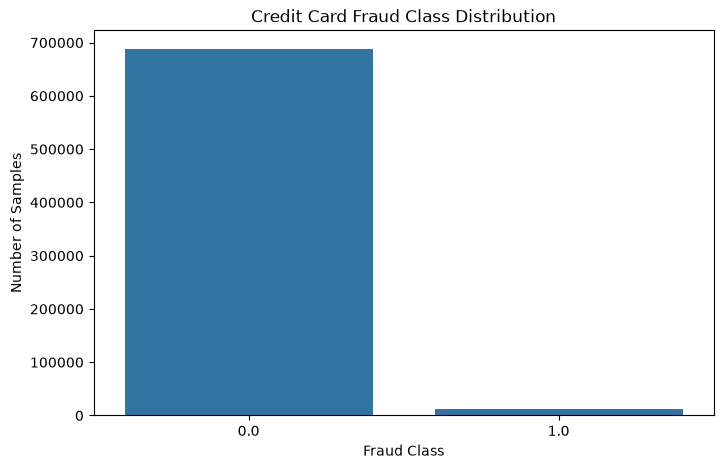

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=train_df, x='is_fraud')

plt.title('Credit Card Fraud Class Distribution')
plt.xlabel('Fraud Class')
plt.ylabel('Number of Samples')

plt.show()

In [14]:
majority_class = class_counts.max()
minority_class = class_counts.min()

imbalance_ratio = majority_class / minority_class

print(f"Imbalance Ratio: {imbalance_ratio:.2f}:1")

Imbalance Ratio: 58.88:1


## Training Models

### Data transforming

In [1]:
def prepare_features(df):
    data = df.copy()
    data = data.drop(columns=['id'], errors='ignore')
            
    ohe_encoded = ohe_encoder.transform(data[cat_cols])
    ohe_df = pd.DataFrame(ohe_encoded, columns=ohe_encoder.get_feature_names_out(cat_cols), index=data.index)
    data = pd.concat([data.drop(columns=cat_cols), ohe_df], axis=1)

    data[num_cols] = scaler.transform(data[num_cols])
    
    data[bool_cols] = data[bool_cols].astype(int)
    
    return data
    

In [16]:
X_test = prepare_features(X_test)

In [17]:
X_test.shape

(139992, 54)

### Xg Boost

In [15]:
scale_pos_weight = (y_train.value_counts()[0] / y_train.value_counts()[1])

In [16]:
from xgboost import XGBClassifier

xgb_model_1 = XGBClassifier(device='cuda', n_jobs = -1, random_state=42, scale_pos_weight=scale_pos_weight)

In [17]:
%%time

xgb_model_1.fit(X_train, y_train)

CPU times: user 3.83 s, sys: 70.2 ms, total: 3.9 s
Wall time: 877 ms


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [23]:
xgb_model_1.score(X_test, y_test)

0.9115592319561118

In [21]:
test_df = prepare_features(test)
test_df

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,...,channel_Online,channel_POS,device_type_ATM Machine,device_type_Android Phone,device_type_Mac,device_type_POS Terminal,device_type_Smart Watch,device_type_Tablet,device_type_Windows PC,device_type_iPhone
0,-0.251313,-0.335290,0.678301,0.368708,-1.767264,-0.357895,-0.171186,-0.295234,-0.324930,1.345335,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2.733594,-0.182439,-1.322743,-0.594370,0.921253,-1.307685,0.035437,-0.295234,-0.711373,-0.401665,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.288486,0.887518,0.011286,0.155265,-0.512623,1.318206,-0.252313,-0.295234,0.171925,-1.420748,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-0.335436,0.043653,-0.655728,2.646875,0.562784,0.144936,-0.080480,-0.295234,-0.895394,-0.547248,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,-0.295892,-0.954656,0.011286,1.001293,0.562784,0.815376,-0.114321,-0.295234,0.098317,0.326252,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299979,-0.259348,-0.341659,-1.989757,-0.417935,-0.691857,0.536026,-0.462515,3.159834,-1.539465,0.471835,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
299980,-0.348069,-0.628255,1.345315,-1.064291,-1.229560,-0.693115,0.192885,-0.295234,-0.067302,-1.129581,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
299981,-0.171208,-0.360766,0.678301,1.885191,-0.512623,-1.363555,-0.078491,3.159834,1.064424,1.199752,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
299982,-0.370382,-0.777922,0.011286,0.281782,-1.229560,-1.307685,0.420857,-0.295234,-0.720574,-1.275165,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [22]:
xgb_model_1.predict(test_df)

array([0, 0, 0, ..., 0, 0, 0], shape=(299984,))

### Catboost

In [19]:
from catboost import CatBoostClassifier

cat_model_2 = CatBoostClassifier(task_type="GPU", thread_count=1, random_seed=42, auto_class_weights='Balanced', verbose=False, allow_writing_files=False)

In [23]:
%%time

cat_model_2.fit(X, y, cat_features=cat_cols)

CPU times: user 45.8 s, sys: 2.27 s, total: 48.1 s
Wall time: 41.6 s


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', random_seed=42, task_type='GPU', thread_count=1, verbose=False)

In [24]:
cat_model_2.score(X, y)

np.float64(0.8897508429053089)

### LightGBM

In [29]:
from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(n_jobs=-1, random_state=42, scale_pos_weight=scale_pos_weight)

In [30]:
%%time

lgbm_model.fit(X_train, y_train)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 9351, number of negative: 550617
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.063768 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1780
[LightGBM] [Info] Number of data points in the train set: 559968, number of used features: 54
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.016699 -> initscore=-4.075556
[LightGBM] [Info] Start training from score -4.075556
CPU times: user 1min 25s, sys: 454 ms, total: 1min 26s
Wall time: 6.7 s


,random_state,42
,n_jobs,-1
,scale_pos_weight,np.float64(58.88322104587745)
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None


In [31]:
lgbm_model.score(X_test, y_test)

0.8720926910109149

### Random Forest

In [3]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_jobs=-1, class_weight='balanced', random_state=42)

In [4]:
%%time
rf_model.fit(X_train, y_train)

CPU times: user 5min 25s, sys: 2.91 s, total: 5min 28s
Wall time: 25.6 s


,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [5]:
rf_model.score(X_test, y_test)

0.9856634664837991

## Hyper parameter tunining

In [13]:
train_inputs = X_train
train_targets = y_train
val_inputs = X_test
val_targets = y_test

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

def test_params(ModelClass, **params):
    model = ModelClass(**params).fit(train_inputs, train_targets)
    train_rmse = mean_squared_error(model.predict(train_inputs), train_targets)
    val_rmse = mean_squared_error(model.predict(val_inputs), val_targets)
    return train_rmse, val_rmse

def test_param_and_plot_1(ModelClass, param_name, param_values, **other_params):
    train_errors, val_errors = [], [] 
    for value in param_values:
        params = dict(other_params)
        params[param_name] = value
        train_rmse, val_rmse = test_params(ModelClass, **params)
        train_errors.append(train_rmse)
        val_errors.append(val_rmse)
    
    plt.figure(figsize=(10,6))
    plt.title('Overfitting curve: ' + param_name)
    plt.plot(param_values, train_errors, 'b-o')
    plt.plot(param_values, val_errors, 'r-o')
    plt.xlabel(param_name)
    plt.ylabel('RMSE')
    plt.legend(['Training', 'Validation'])

### XG Boost

In [43]:
params = {
    'random_state': 42,
    'n_jobs': 1,
    'device': 'cuda',
    'scale_pos_weight': scale_pos_weight,
}

In [39]:
from xgboost import XGBClassifier

CPU times: user 21.2 s, sys: 420 ms, total: 21.6 s
Wall time: 4.2 s


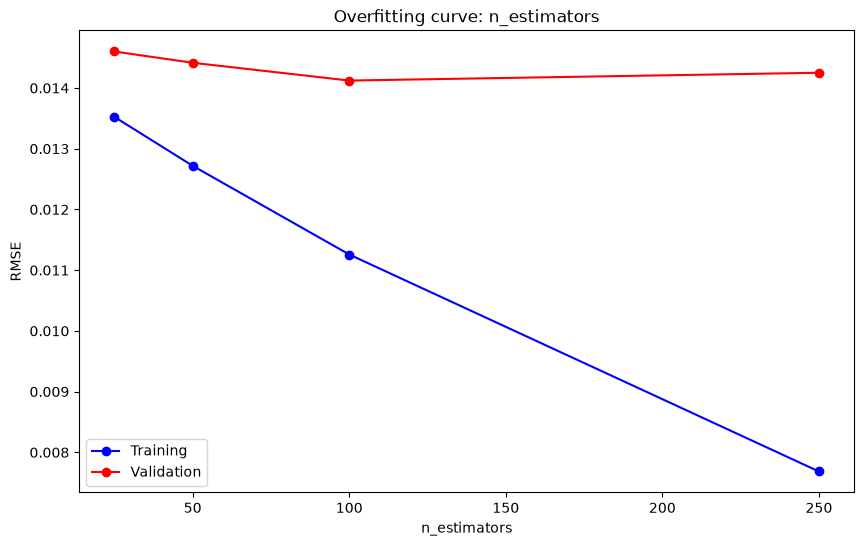

In [10]:
%%time 

test_param_and_plot(XGBClassifier, 'n_estimators', [25, 50, 100, 250], **params) # number of trees

CPU times: user 26.8 s, sys: 575 ms, total: 27.4 s
Wall time: 4.7 s


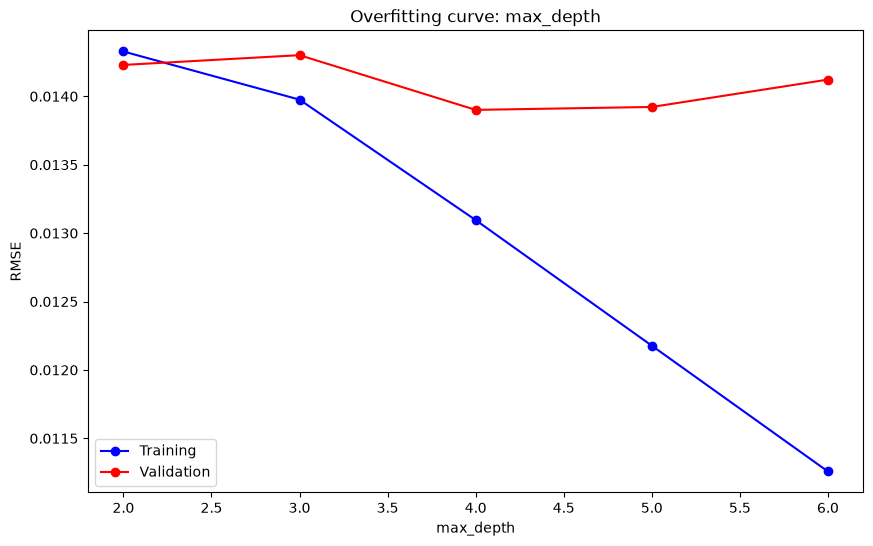

In [12]:
%%time 

test_param_and_plot(XGBClassifier,  'max_depth', [ 2, 3, 4, 5, 6], **params) # complexitity of a tree

CPU times: user 27.4 s, sys: 436 ms, total: 27.9 s
Wall time: 5.44 s


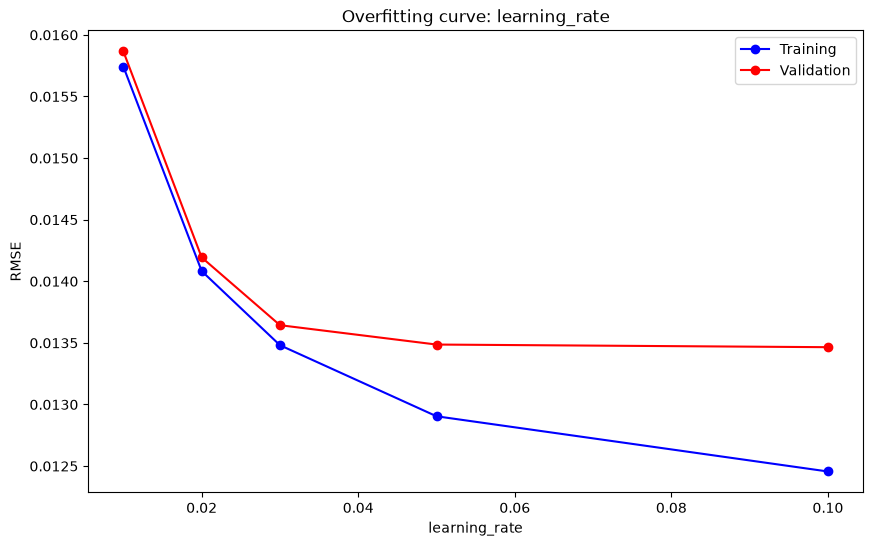

In [14]:
%%time 

test_param_and_plot(XGBClassifier, 'learning_rate', [0.01, 0.02, 0.03, 0.05, 0.1], **params) # [0.05, 0.1, 0.25, 0.40, 0.55] # [0.05, 0.1, 0.25, 0.40, 0.55]

CPU times: user 29.8 s, sys: 561 ms, total: 30.3 s
Wall time: 5.7 s


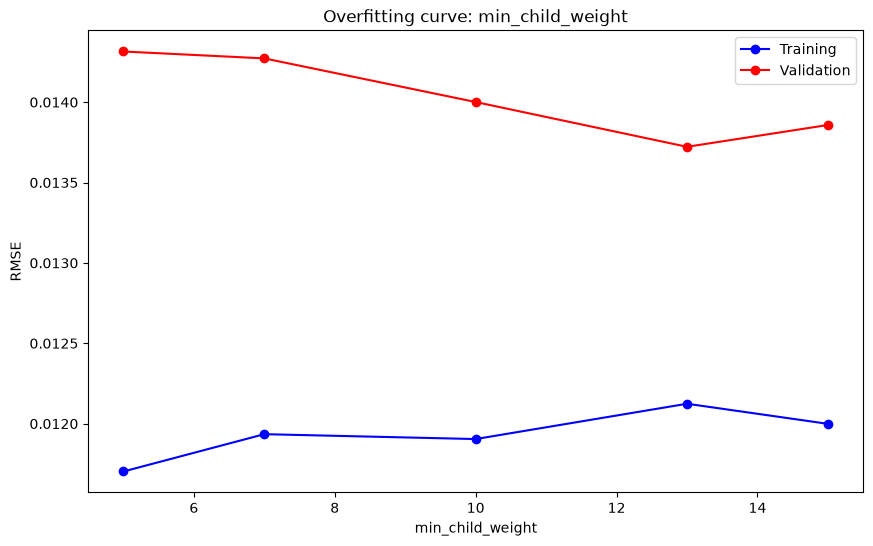

In [19]:
%%time 

test_param_and_plot(XGBClassifier, 'min_child_weight', [5, 7, 10, 13, 15], **params) # min children to branch

CPU times: user 33.7 s, sys: 596 ms, total: 34.3 s
Wall time: 6.54 s


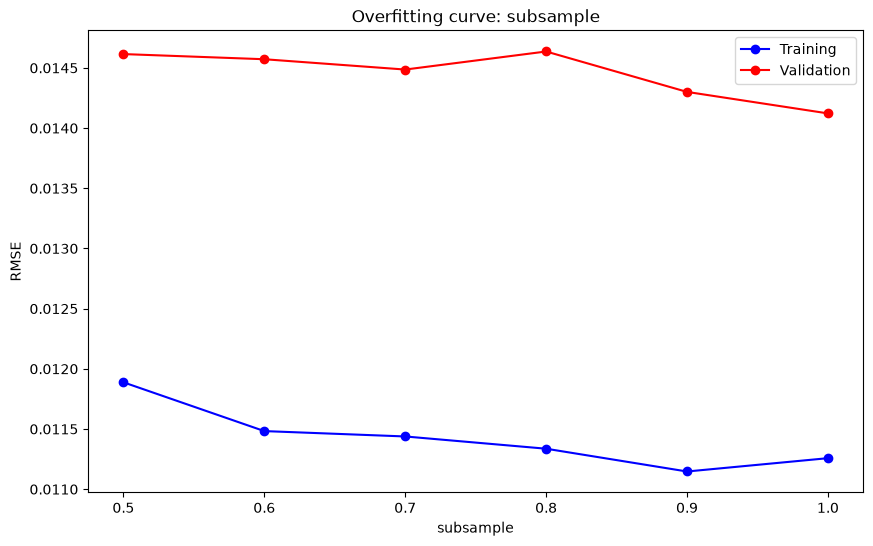

In [20]:
%%time 

test_param_and_plot(XGBClassifier, 'subsample', [0.5, 0.6, 0.7, 0.8, 0.9, 1.0], **params) # how much sample for each tree

CPU times: user 38.8 s, sys: 775 ms, total: 39.6 s
Wall time: 7.29 s


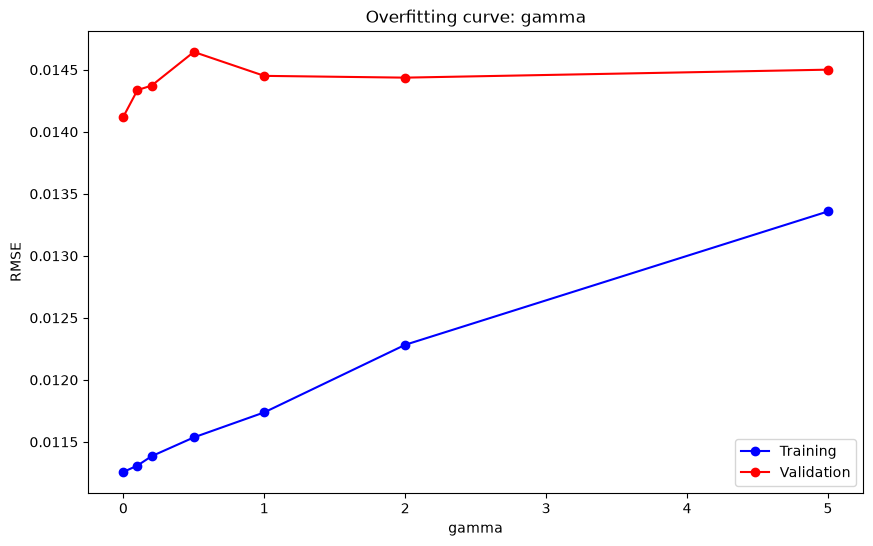

In [21]:
%%time 

test_param_and_plot(XGBClassifier, 'gamma', [0.1, 0.2, 0.5, 1, 2, 5], **params) # how much loss reduction for split

In [44]:
hyper_params = {
    'n_estimators' : 100,
    'max_depth': 4,
    'learning_rate': 1,
    'min_child_weight': 13,
    'subsample': 1,
    'gamma': 1
}

In [45]:
from xgboost import XGBClassifier

xgb_model_hypr_1 = XGBClassifier(**params, **hyper_params)

In [46]:
xgb_model_hypr_1.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [47]:
xgb_model_hypr_1.score(X_test, y_test)

0.9001014343676782

### Cat Boost

In [59]:
params = {
        'task_type': "GPU", 
        'thread_count': 1, 
        'random_seed': 42, 
        'auto_class_weights':'Balanced',
        'verbose': False,
        'allow_writing_files': False
}

In [54]:
from catboost import CatBoostClassifier

CPU times: user 28.6 s, sys: 7.17 s, total: 35.7 s
Wall time: 15.7 s


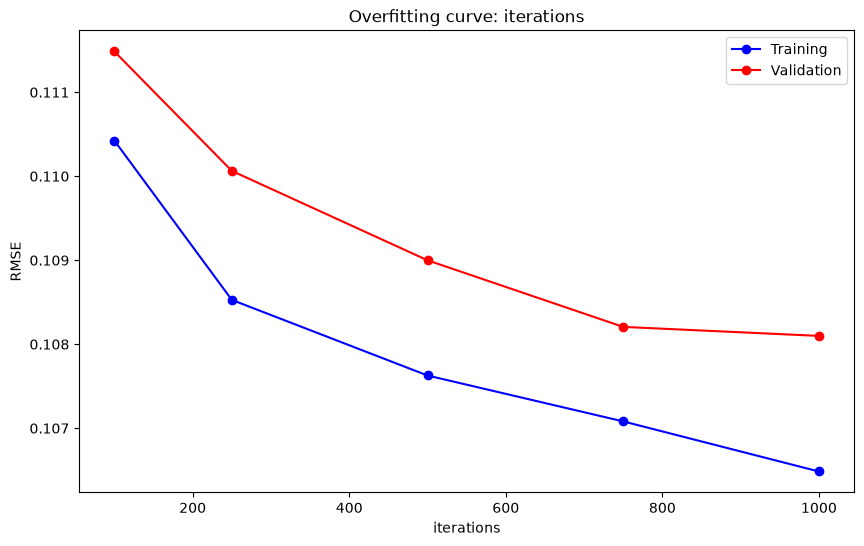

In [61]:
%%time

test_param_and_plot(CatBoostClassifier, 'iterations', [100, 250, 500, 750, 1000], **params)

CPU times: user 7min 32s, sys: 2min 55s, total: 10min 27s
Wall time: 5min 11s


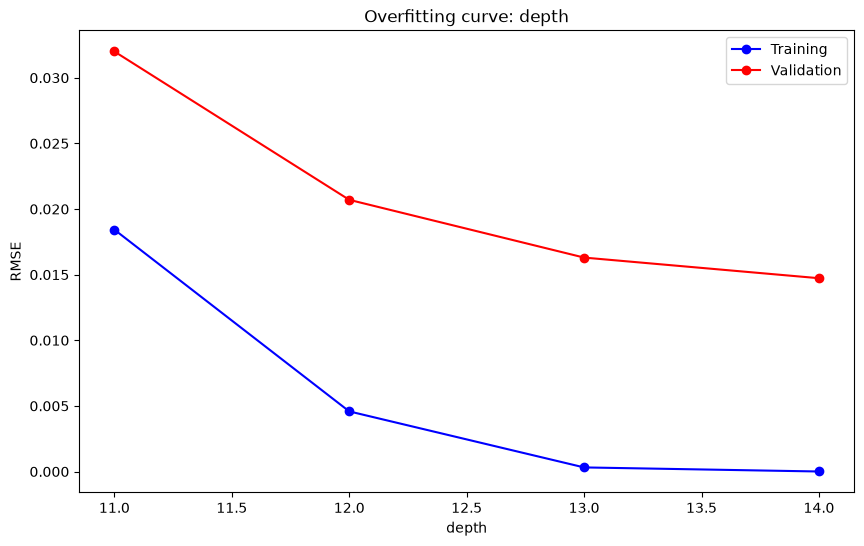

In [73]:
%%time
test_param_and_plot(CatBoostClassifier, 'depth', [11, 12, 13, 14], **params)

CPU times: user 56.8 s, sys: 16.3 s, total: 1min 13s
Wall time: 35 s


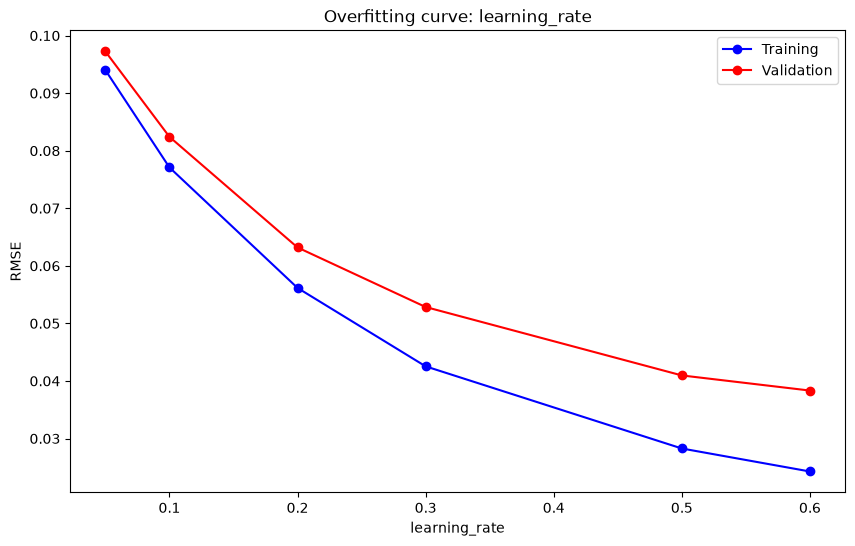

In [67]:
%%time
test_param_and_plot(CatBoostClassifier, 'learning_rate', [0.05, 0.1, 0.2, 0.3, 0.5, 0.6], **params)

CPU times: user 58.5 s, sys: 16.3 s, total: 1min 14s
Wall time: 35.6 s


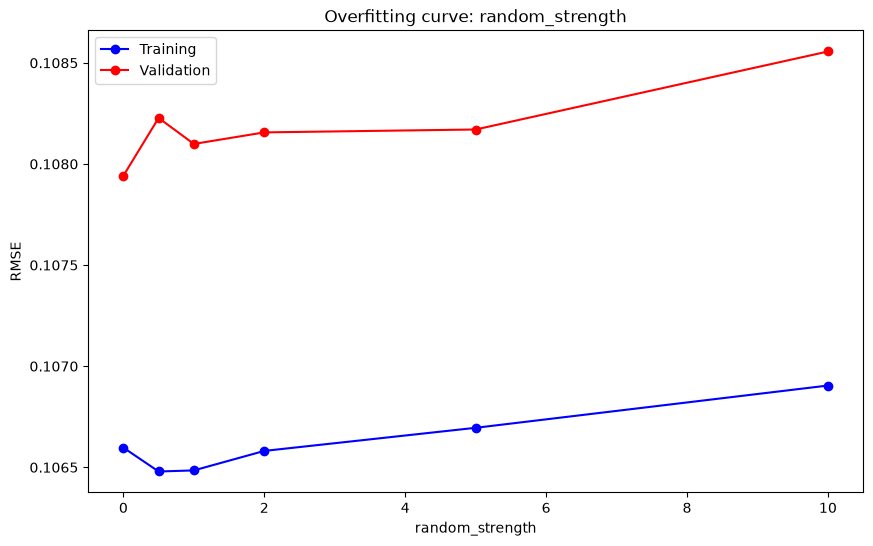

In [72]:
%%time
test_param_and_plot(CatBoostClassifier, 'random_strength', [0, 0.5, 1, 2, 5, 10], **params)

In [74]:
hyper_params = {
    'iterations': 750,
    'depth': 14,
    'learning_rate': 0.6,
    'random_strength': 0,
}

In [75]:
from catboost import CatBoostClassifier

cat_model_hypr_1 = CatBoostClassifier(**params, **hyper_params)

In [78]:
%%time

cat_model_hypr_1.fit(X_train, y_train)

KeyboardInterrupt: 

In [79]:
cat_model_hypr_1.score(X_test, y_test)

np.float64(0.9844419681124635)

### Stacking

In [7]:
%%time

from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

estimators = [
    ('xgb', xgb_model_1),
    ('lgbm', lgbm_model),
    ('catboost', cat_model)
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

stack_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(
        class_weight='balanced',
        max_iter=1000
    ),
    cv=cv,
    stack_method='predict_proba',
    n_jobs=1
)

stack_model.fit(X_train, y_train)

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 9351, number of negative: 550617
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.024039 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1780
[LightGBM] [Info] Number of data points in the train set: 559968, number of used features: 54
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.016699 -> initscore=-4.075556
[LightGBM] [Info] Start training from score -4.075556
Learning rate set to 0.023803
0:	learn: 0.6739169	total: 6.79ms	remaining: 6.78s
1:	learn: 0.6560034	total: 13.2ms	remaining: 6.57s
2:	learn: 0.6391873	total: 19.5ms	remaining: 6.5s
3:	learn: 0.6230800	total: 25.8ms	remaining: 6.42s
4:	learn: 0.6081492	total: 32.2ms	remaining: 6.41s
5:	learn: 0.5946277	total: 38.5ms	remaining: 6.37s
6:	learn: 0.5820387	total:

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('xgb', ...), ('lgbm', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...max_iter=1000)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",StratifiedKFo... shuffle=True)
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'predict_proba'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",1
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[float64](2,)","[0.,1.]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[XGBClassifier...ree=None, ...), LGBMClassifie...322104587745)), CatBoostClass...sk_type='GPU')]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose 

In [8]:
import pandas as pd

weights = pd.DataFrame({
    'Model': ['XGBoost', 'LightGBM', 'CatBoost'],
    'Coefficient': stack_model.final_estimator_.coef_[0]
})

print(weights)

      Model  Coefficient
0   XGBoost     2.210367
1  LightGBM     0.497216
2  CatBoost     5.337266


In [9]:
from sklearn.metrics import (
    classification_report,
    average_precision_score,
    confusion_matrix
)

y_pred = stack_model.predict(X_test)
y_proba = stack_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print('Average Precision:', average_precision_score(y_test, y_proba))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       1.00      0.89      0.94    137654
         1.0       0.11      0.85      0.20      2338

    accuracy                           0.89    139992
   macro avg       0.55      0.87      0.57    139992
weighted avg       0.98      0.89      0.93    139992

Average Precision: 0.48222642436804836
[[122034  15620]
 [   356   1982]]


In [12]:
from sklearn.metrics import classification_report

for threshold in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_pred = (y_proba >= threshold).astype(int)

    print(f'\nThreshold: {threshold}')
    print(classification_report(y_test, y_pred))


Threshold: 0.3
              precision    recall  f1-score   support

         0.0       1.00      0.82      0.90    137654
         1.0       0.08      0.90      0.15      2338

    accuracy                           0.82    139992
   macro avg       0.54      0.86      0.52    139992
weighted avg       0.98      0.82      0.89    139992


Threshold: 0.4
              precision    recall  f1-score   support

         0.0       1.00      0.86      0.92    137654
         1.0       0.10      0.88      0.17      2338

    accuracy                           0.86    139992
   macro avg       0.55      0.87      0.55    139992
weighted avg       0.98      0.86      0.91    139992


Threshold: 0.5
              precision    recall  f1-score   support

         0.0       1.00      0.89      0.94    137654
         1.0       0.11      0.85      0.20      2338

    accuracy                           0.89    139992
   macro avg       0.55      0.87      0.57    139992
weighted avg       0.98   

In [13]:
thresholds = [0.70, 0.75, 0.80, 0.85, 0.90, 0.95]

for threshold in thresholds:
    y_pred = (y_proba >= threshold).astype(int)

    print(f'\nThreshold: {threshold}')
    print(classification_report(y_test, y_pred))


Threshold: 0.7
              precision    recall  f1-score   support

         0.0       1.00      0.93      0.96    137654
         1.0       0.16      0.78      0.27      2338

    accuracy                           0.93    139992
   macro avg       0.58      0.85      0.61    139992
weighted avg       0.98      0.93      0.95    139992


Threshold: 0.75
              precision    recall  f1-score   support

         0.0       1.00      0.94      0.97    137654
         1.0       0.18      0.76      0.29      2338

    accuracy                           0.94    139992
   macro avg       0.59      0.85      0.63    139992
weighted avg       0.98      0.94      0.96    139992


Threshold: 0.8
              precision    recall  f1-score   support

         0.0       1.00      0.95      0.97    137654
         1.0       0.21      0.72      0.32      2338

    accuracy                           0.95    139992
   macro avg       0.60      0.84      0.65    139992
weighted avg       0.98  

### Feature Enginnering

In [119]:
import numpy as np
import pandas as pd

def feature_engineering(df):
    df = df.copy()

    # Amount features
    df['log_amount'] = np.log1p(df['amount_usd'])
    df['log_balance'] = np.log1p(df['account_balance_usd'])

    df['amount_balance_ratio'] = (
        df['amount_usd'] / (df['account_balance_usd'] + 1)
    )

    df['balance_after_transaction'] = (
        df['account_balance_usd'] - df['amount_usd']
    )

    # Transaction frequency / recency
    df['transaction_velocity'] = (
        df['txn_count_last_24h'] /
        (df['hours_since_last_txn'] + 1)
    )

    df['rapid_transaction'] = (
        df['hours_since_last_txn'] <= 1
    ).astype(int)

    # Time features
    df['hour_sin'] = np.sin(
        2 * np.pi * df['time_of_day_hour'] / 24
    )

    df['hour_cos'] = np.cos(
        2 * np.pi * df['time_of_day_hour'] / 24
    )

    df['day_sin'] = np.sin(
        2 * np.pi * df['day_of_week'] / 7
    )

    df['day_cos'] = np.cos(
        2 * np.pi * df['day_of_week'] / 7
    )

    # Suspicious indicators
    risk_columns = [
        'is_foreign_transaction',
        'is_new_merchant',
        'used_vpn',
        'ip_country_mismatch',
        'billing_shipping_mismatch',
        'is_ai_generated_scam_attempt'
    ]

    df['suspicious_signal_count'] = df[risk_columns].sum(axis=1)

    df['multiple_risk_signals'] = (
        df['suspicious_signal_count'] >= 2
    ).astype(int)

    # Merchant features
    df['new_merchant_risk'] = (
        df['merchant_risk_score'] *
        df['is_new_merchant'].astype(int)
    )

    # Distance features
    df['amount_distance_ratio'] = (
        df['amount_usd'] *
        (df['distance_from_home_km'] + 1)
    )

    # CVV features
    df['multiple_cvv_attempts'] = (
        df['cvv_retry_count'] >= 2
    ).astype(int)

    return df

### Cat Boost hypr

In [ ]:
# clasdification

from sklearn.metrics import mean_squared_error

def test_params(ModelClass, **params):
    model = ModelClass(**params).fit(train_inputs, train_targets, cat_features=cat_cols)
    train_rmse = mean_squared_error(model.predict(train_inputs), train_targets)
    val_rmse = mean_squared_error(model.predict(val_inputs), val_targets)
    return train_rmse, val_rmse

In [4]:
from catboost import CatBoostClassifier

In [5]:
train_inputs = X_train
train_targets = y_train
val_inputs = X_test
val_targets = y_test

In [120]:
from pathlib import Path
import pandas as pd

data_dir = Path('datasets/predicting_credit_card_fraud')

train_df = pd.read_csv(data_dir/'train.csv')
test = pd.read_csv(data_dir/'test.csv')
sample_submission = pd.read_csv(data_dir/'sample_submission.csv')

In [121]:
train_df = feature_engineering(train_df)

In [122]:
X = train_df.drop(columns=['id', 'is_fraud'])
y = train_df['is_fraud']

In [123]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y) 

In [124]:
from sklearn.model_selection import train_test_split

X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [125]:
cat_cols = X_train.select_dtypes(include='str').columns.tolist()

In [126]:
cat_model_4 = CatBoostClassifier(**params_reg)

In [127]:
%%time
cat_model_4.fit(X_test, y_test, cat_features=cat_cols)

CPU times: user 15.4 s, sys: 1.51 s, total: 16.9 s
Wall time: 12.8 s


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', random_seed=42, task_type='GPU', thread_count=1, verbose=False)

In [128]:
from sklearn.metrics import roc_auc_score, average_precision_score

y_proba = cat_model_4.predict_proba(X_test)[:, 1]
sco_mod = cat_model_4.score(X_test, y_test)
roc_auc = roc_auc_score(y_test, y_proba)
prec_sc = average_precision_score(y_test, y_proba)

print('Score:', sco_mod)
print('ROC-AUC:', roc_auc)
print('Precision:', prec_sc)

Score: 0.9222884164809417
ROC-AUC: 0.9830830763580096
Precision: 0.6210900548357412


In [11]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

def test_params(ModelClass, **params):
    model = ModelClass(**params)

    model.fit(X_fit, y_fit, cat_features=cat_cols)

    train_proba = model.predict_proba(X_fit)[:, 1]
    val_proba = model.predict_proba(X_val)[:, 1]

    scores = {
        'train_ap': average_precision_score(y_fit, train_proba),
        'val_ap': average_precision_score(y_val, val_proba),

        'train_roc_auc': roc_auc_score(y_fit, train_proba),
        'val_roc_auc': roc_auc_score(y_val, val_proba)
    }

    return scores

In [12]:
import matplotlib.pyplot as plt

def test_param_and_plot(ModelClass, param_name, param_values, **other_params):

    train_ap, val_ap = [], []
    train_roc, val_roc = [], []

    for value in param_values:

        params = dict(other_params)
        params[param_name] = value

        scores = test_params(ModelClass, **params)

        train_ap.append(scores['train_ap'])
        val_ap.append(scores['val_ap'])

        train_roc.append(scores['train_roc_auc'])
        val_roc.append(scores['val_roc_auc'])

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(param_values, train_ap, 'b-o')
    axes[0].plot(param_values, val_ap, 'r-o')
    axes[0].set_title('Average Precision: ' + param_name)
    axes[0].set_xlabel(param_name)
    axes[0].set_ylabel('Average Precision')
    axes[0].legend(['Training', 'Validation'])
    axes[0].grid(True)

    axes[1].plot(param_values, train_roc, 'b-o')
    axes[1].plot(param_values, val_roc, 'r-o')
    axes[1].set_title('ROC-AUC: ' + param_name)
    axes[1].set_xlabel(param_name)
    axes[1].set_ylabel('ROC-AUC')
    axes[1].legend(['Training', 'Validation'])
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

In [17]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def test_param_and_plot(ModelClass, param_name, param_values, **other_params):

    train_ap, val_ap = [], []
    train_roc, val_roc = [], []

    for value in param_values:

        params = dict(other_params)
        params[param_name] = value

        scores = test_params(ModelClass, **params)

        train_ap.append(scores['train_ap'])
        val_ap.append(scores['val_ap'])

        train_roc.append(scores['train_roc_auc'])
        val_roc.append(scores['val_roc_auc'])

    fig = make_subplots(
        rows=1,
        cols=2,
        subplot_titles=[
            f"Average Precision: {param_name}",
            f"ROC-AUC: {param_name}"
        ]
    )

    # Average Precision
    fig.add_trace(
        go.Scatter(
            x=param_values,
            y=train_ap,
            mode='lines+markers',
            name='Training AP',
            marker=dict(size=8),
            line=dict(width=2),
            hovertemplate=(
                f"<b>{param_name}</b>: %{{x}}<br>"
                "Training AP: %{y:.6f}<extra></extra>"
            )
        ),
        row=1, col=1
    )

    fig.add_trace(
        go.Scatter(
            x=param_values,
            y=val_ap,
            mode='lines+markers',
            name='Validation AP',
            marker=dict(size=8),
            line=dict(width=2),
            hovertemplate=(
                f"<b>{param_name}</b>: %{{x}}<br>"
                "Validation AP: %{y:.6f}<extra></extra>"
            )
        ),
        row=1, col=1
    )

    # ROC-AUC
    fig.add_trace(
        go.Scatter(
            x=param_values,
            y=train_roc,
            mode='lines+markers',
            name='Training ROC-AUC',
            marker=dict(size=8),
            line=dict(width=2),
            hovertemplate=(
                f"<b>{param_name}</b>: %{{x}}<br>"
                "Training ROC-AUC: %{y:.6f}<extra></extra>"
            )
        ),
        row=1, col=2
    )

    fig.add_trace(
        go.Scatter(
            x=param_values,
            y=val_roc,
            mode='lines+markers',
            name='Validation ROC-AUC',
            marker=dict(size=8),
            line=dict(width=2),
            hovertemplate=(
                f"<b>{param_name}</b>: %{{x}}<br>"
                "Validation ROC-AUC: %{y:.6f}<extra></extra>"
            )
        ),
        row=1, col=2
    )

    fig.update_layout(
        title=f"Hyperparameter Tuning: {param_name}",
        template="plotly_white",
        height=600,
        width=1200,
        hovermode="closest",
        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="center",
            x=0.5
        )
    )

    fig.update_xaxes(title_text=param_name, row=1, col=1)
    fig.update_xaxes(title_text=param_name, row=1, col=2)

    fig.update_yaxes(title_text="Average Precision", row=1, col=1)
    fig.update_yaxes(title_text="ROC-AUC", row=1, col=2)

    fig.show()

In [59]:
params_reg = {
        'task_type': "GPU", 
        'thread_count': 1, 
        'random_seed': 42, 
        'auto_class_weights':'Balanced',
        'verbose': False,
        'allow_writing_files': False
}

In [33]:
params = {
        'task_type': "GPU", 
        'thread_count': 1, 
        'random_seed': 42, 
        'auto_class_weights':'Balanced',
        'verbose': False,
        'allow_writing_files': False,
        'depth': 4,
        'learning_rate': 0.05,
        'iterations': 1000,
        'l2_leaf_reg': 5,
        'random_strength': 1
}

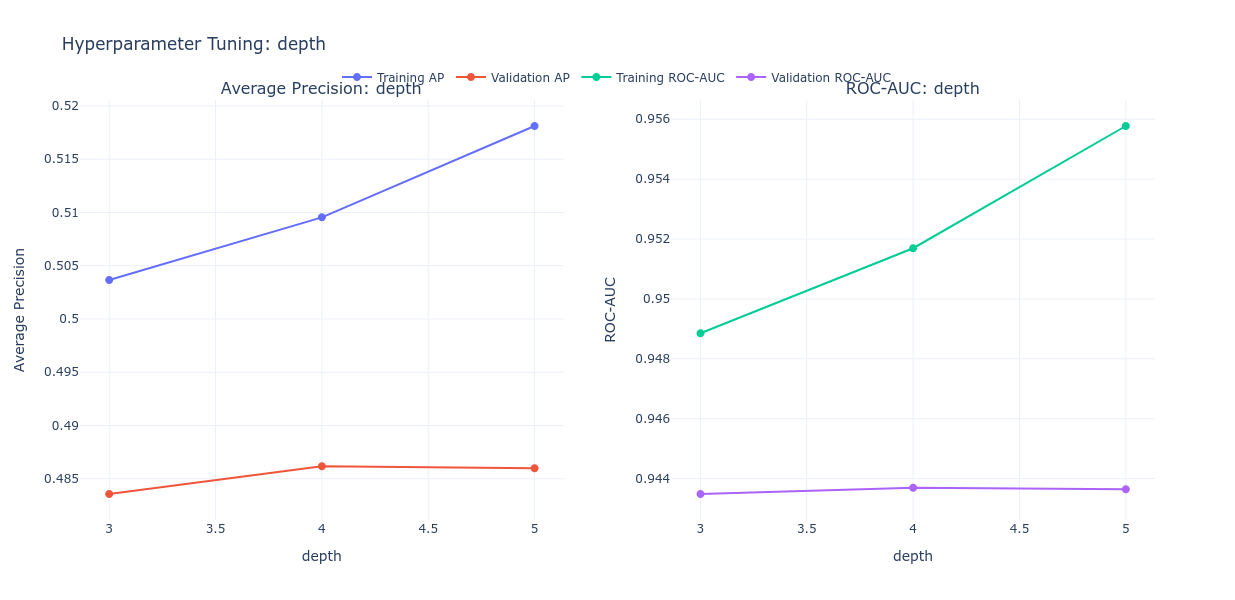

CPU times: user 1min 7s, sys: 5.22 s, total: 1min 12s
Wall time: 55 s


In [19]:
%%time

test_param_and_plot(CatBoostClassifier, 'depth', [3, 4, 5], **params)

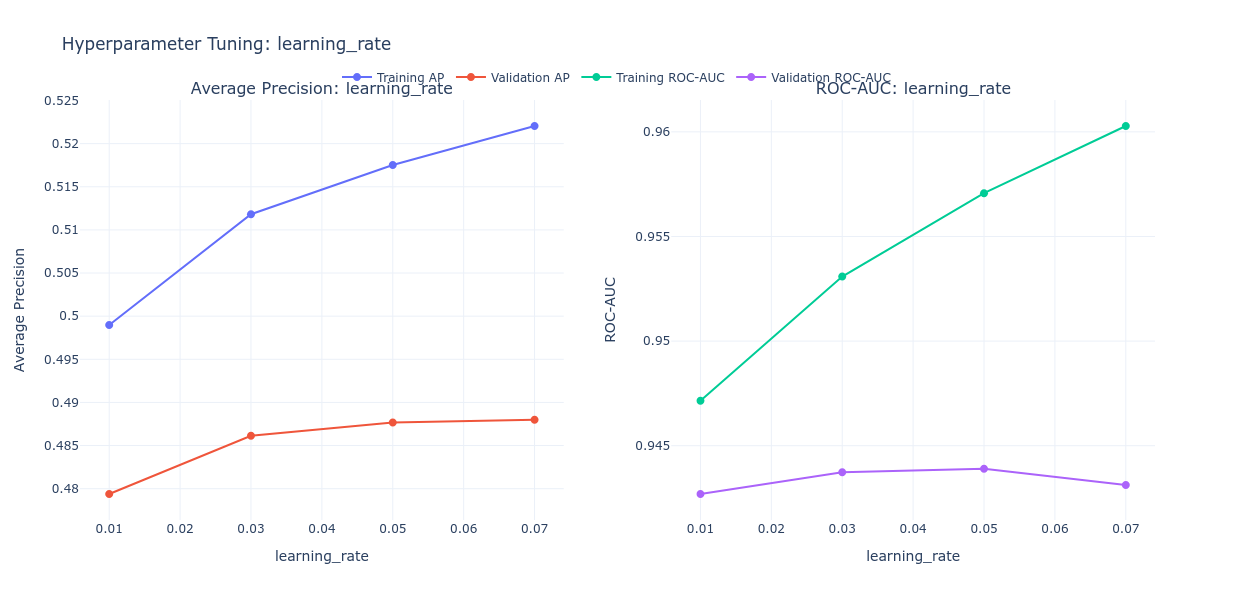

CPU times: user 1min 28s, sys: 6.98 s, total: 1min 35s
Wall time: 1min 11s


In [22]:
%%time

test_param_and_plot(CatBoostClassifier, 'learning_rate', [0.01, 0.03, 0.05, 0.07], **params)

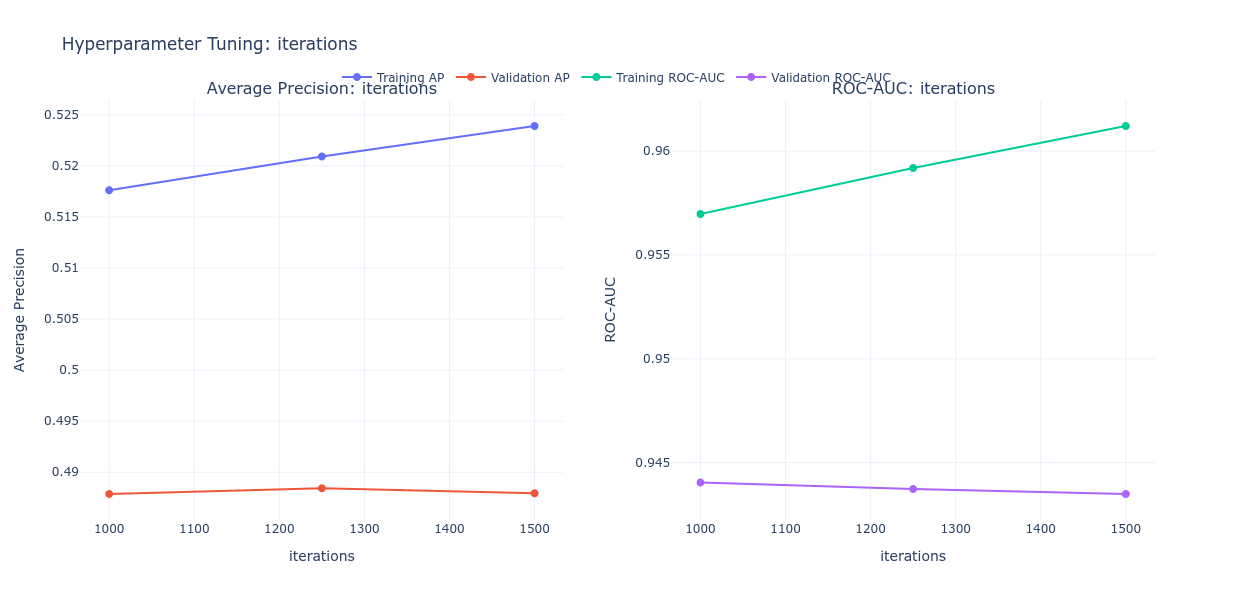

CPU times: user 1min 18s, sys: 5.51 s, total: 1min 24s
Wall time: 1min 4s


In [26]:
%%time

test_param_and_plot(CatBoostClassifier, 'iterations', [1000, 1250, 1500], **params)

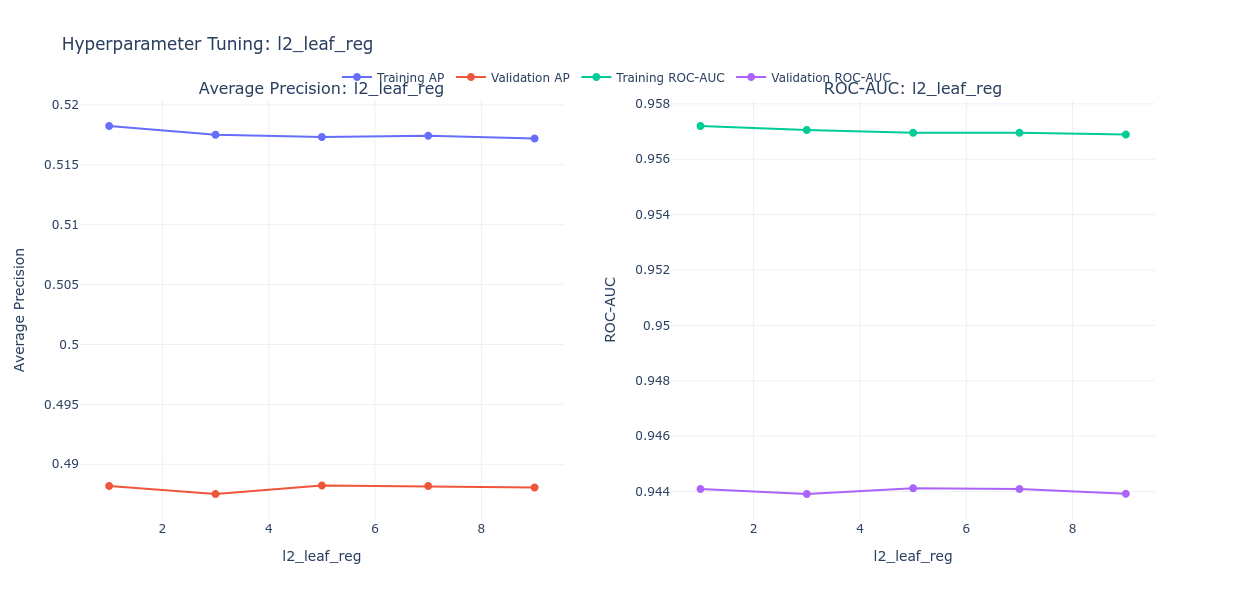

CPU times: user 1min 47s, sys: 7.88 s, total: 1min 55s
Wall time: 1min 28s


In [29]:
%%time

test_param_and_plot(CatBoostClassifier, 'l2_leaf_reg', [1, 3, 5, 7, 9], **params)

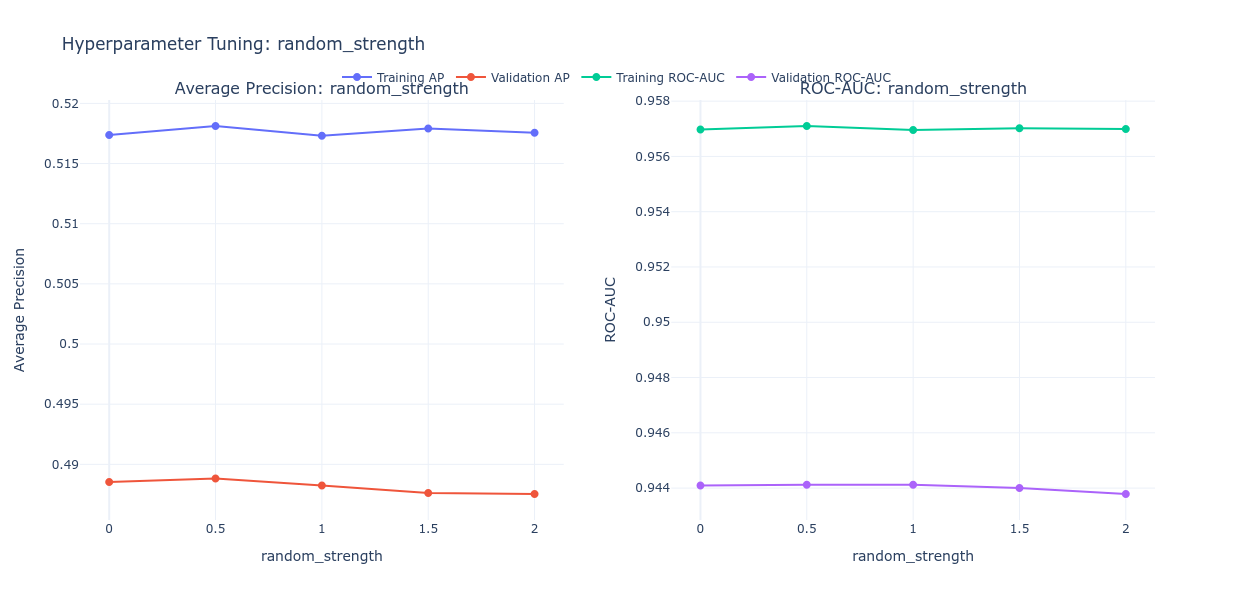

CPU times: user 1min 48s, sys: 7.82 s, total: 1min 56s
Wall time: 1min 28s


In [32]:
%%time

test_param_and_plot(CatBoostClassifier, 'random_strength', [0, 0.5, 1, 1.5, 2], **params)

In [34]:
hypr_params = {
    'depth': 4,
    'learning_rate': 0.05,
    'iterations': 1000,
    'l2_leaf_reg': 5,
    'random_strength': 1
}

In [35]:
cat_model_3 = CatBoostClassifier(**params)

In [36]:
%%time

cat_model_3.fit(X_train, y_train, cat_features=cat_cols)

CPU times: user 24 s, sys: 1.55 s, total: 25.6 s
Wall time: 21.6 s


CatBoostClassifier(allow_writing_files=False, auto_class_weights='Balanced', depth=4, iterations=1000, l2_leaf_reg=5, learning_rate=0.05, random_seed=42, random_strength=1, task_type='GPU', thread_count=1, verbose=False)

In [38]:
from sklearn.metrics import roc_auc_score

y_proba = cat_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_proba)

print('ROC-AUC:', roc_auc)

ROC-AUC: 0.954777014158172


## Saving and getting the model

In [23]:
import joblib
from pathlib import Path

model_dir = Path('./models')
model_dir.mkdir(parents=True, exist_ok=True)

feature_cols = X_train.columns.tolist()

artifacts = {
    'xgb_classifier': xgb_model_1,

    'ohe_encoder': ohe_encoder,

    'scaler': scaler,

    'num_cols': num_cols.tolist(),
    'cat_cols': cat_cols.tolist(),
    'bool_cols': bool_cols.tolist(),
    
    'feature_cols': feature_cols,

    'X_test': X_test,
    'y_test': y_test,
    'X_train': X_train,
    'y_train': y_train,
    'test': test,
}

artifact_path = model_dir / 'predicting_credit_card_fraud.joblib'

joblib.dump(artifacts, artifact_path)

print(f"Artifacts saved to: {artifact_path}")


Artifacts saved to: models/predicting_credit_card_fraud.joblib


In [3]:
import joblib

artifacts = joblib.load('./models/predicting_credit_card_fraud.joblib')

xgb_model_1 = artifacts['xgb_classifier'] 
cat_model = artifacts['cat_model'] 
lgbm_model = artifacts['lgbm_model'] 

cat_model_2 = artifacts['cat_model_2'] 

xgb_model_hypr_1 = artifacts['xgb_model_hypr_1'] 

stack_model = artifacts['stack_model'] 

ohe_encoder = artifacts['ohe_encoder']

scaler = artifacts['scaler']

num_cols = artifacts['num_cols']
cat_cols = artifacts['cat_cols']
bool_cols = artifacts['bool_cols']

scale_pos_weight = artifacts['scale_pos_weight'] 

feature_cols = artifacts['feature_cols'] 

X_test = artifacts['X_test']
y_test = artifacts['y_test']
X_train = artifacts['X_train']
y_train = artifacts['y_train'] 

test = artifacts['test'] 
test_df = artifacts['test_df'] 

X = artifacts['X'] 
y = artifacts['y'] 

train_df = artifacts['train_df'] 

In [43]:
artifacts['cat_model_3'] = cat_model_3

In [44]:
joblib.dump(artifacts, './models/predicting_credit_card_fraud.joblib')

['./models/predicting_credit_card_fraud.joblib']

## Creating the submission file

In [41]:
from sklearn.metrics import roc_auc_score, average_precision_score

y_proba = cat_model_3.predict_proba(X_test)[:, 1]
sco_mod = cat_model_3.score(X_test, y_test)
roc_auc = roc_auc_score(y_test, y_proba)
prec_sc = average_precision_score(y_test, y_proba)

print('Score:', sco_mod)
print('ROC-AUC:', roc_auc)
print('Precision:', prec_sc)

Score: 0.8873078461626379
ROC-AUC: 0.9436572651508451
Precision: 0.5087871576957862


In [42]:
from sklearn.metrics import roc_auc_score

y_proba = cat_model_3.predict_proba(X)[:, 1]
roc_auc = roc_auc_score(y, y_proba)

print('ROC-AUC:', roc_auc)

ROC-AUC: 0.9527766429337043


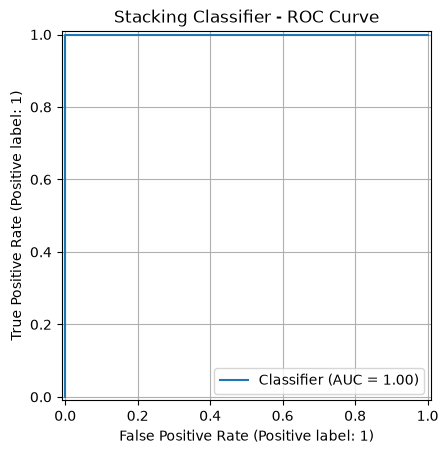

In [24]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_predictions(y, y_proba)

plt.title('Stacking Classifier - ROC Curve')
plt.grid()
plt.show()

In [45]:
def create_submission(model, test_df):
    ids = test_df['id'].copy()
    test_df = prepare_features(test_df)
    predictions = model.predict_proba(test_df)[:, 1]
        
    submission = pd.DataFrame({
        'id': ids,
        'is_fraud': predictions
    })

    return submission


In [46]:
import pandas as pd

def prepare_features(df):
    data = df.copy()
    data = data.drop(columns=['id'], errors='ignore')
            
    ohe_encoded = ohe_encoder.transform(data[cat_cols])
    ohe_df = pd.DataFrame(ohe_encoded, columns=ohe_encoder.get_feature_names_out(cat_cols), index=data.index)
    data = pd.concat([data.drop(columns=cat_cols), ohe_df], axis=1)

    data[num_cols] = scaler.transform(data[num_cols])
    
    data[bool_cols] = data[bool_cols].astype(int)
    
    return data
    

In [47]:
def create_submission_2(model, test_df):
    ids = test_df['id'].copy()
    test_df = test_df.drop(columns='id')
    predictions = model.predict_proba(test_df)[:, 1]
        
    submission = pd.DataFrame({
        'id': ids,
        'is_fraud': predictions
    })

    return submission


In [129]:
test = feature_engineering(test)

In [130]:
submission = create_submission_2(cat_model_4, test)

In [131]:
submission.to_csv('datasets/predicting_credit_card_fraud/submissions/submission_20_catboosr_feature_eng.csv', index=False)

In [53]:
X.head(5).to_csv('data.csv')